# Lab 3 - Task 4: Parametric VaR (IndusInd Bank, `INDUSINDBK.NS`)

This notebook covers **Task 4 only**. It computes one-day parametric (normal) VaR at 90%, 95% and 99% using two volatility estimates:

1. **Historical volatility** over a rolling window of up to 200 trading days.
2. **GARCH(1,1)** one-day-ahead volatility (EWMA is computed as a cross-check).

**Conventions (as in the sample notebook):** simple daily returns in decimal form, all volatilities daily (not annualised), VaR expressed as a positive loss fraction.

**Parametric VaR formula (normal distribution):**

$$
\text{VaR}_c = -\left(\mu_d - z_c\,\sigma_d\right) = z_c\,\sigma_d - \mu_d,
\qquad z_c = \Phi^{-1}(c)
$$

with $z_{0.90}=1.2816$, $z_{0.95}=1.6449$, $z_{0.99}=2.3263$.

In [1]:
%pip install numpy pandas matplotlib yfinance arch statsmodels scipy -q

Note: you may need to restart the kernel to use updated packages.


## 1. Setup and parameters

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.stats import norm, skew, kurtosis, jarque_bera
from arch import arch_model
from statsmodels.stats.diagnostic import het_arch

ticker      = "INDUSINDBK.NS"
start_date  = "2020-06-01"      # long history for GARCH (same as sample notebook)
end_date    = "2026-11-14"      # yfinance end date is exclusive -> last data point 13 Nov 2026

VAR_SAMPLE  = 200               # most recent 200 daily returns (Tasks 3-6)
HV_WINDOW   = 200               # historical-vol window for Task 4 (must be <= 200)
lam         = 0.94              # EWMA decay factor (cross-check only)
conf_levels = [0.90, 0.95, 0.99]
USE_MEAN    = True              # True: VaR = z*sigma - mu ; False: zero-mean VaR = z*sigma

assert HV_WINDOW <= VAR_SAMPLE <= 200

## 2. Data and returns

In [3]:
data = yf.download(ticker, start=start_date, end=end_date, auto_adjust=True, progress=False)
price = data["Close"].squeeze()
returns = price.pct_change().dropna()          # simple daily returns, decimal form

var_returns = returns.iloc[-VAR_SAMPLE:]        # most recent 200 trading days

print("Long sample (volatility models):", returns.index[0].date(), "to", returns.index[-1].date(), f"({len(returns)} returns)")
print("VaR sample (last 200 days)     :", var_returns.index[0].date(), "to", var_returns.index[-1].date(), f"({len(var_returns)} returns)")

Long sample (volatility models): 2020-06-02 to 2026-11-12 (1599 returns)
VaR sample (last 200 days)     : 2026-01-20 to 2026-11-12 (200 returns)


## 3. Volatility estimate 1 - Historical volatility

$$
\mu_d = \frac{1}{X}\sum_{i=1}^{X} r_{T-i+1},
\qquad
\sigma_d = \sqrt{\frac{1}{X-1}\sum_{i=1}^{X}(r_{T-i+1}-\mu_d)^2}
$$

computed over the most recent $X$ = `HV_WINDOW` returns. The mean $\mu_d$ is estimated over the **same window**.

**Choice of window (200 days).** The 200-day window uses the full VaR sample used in Tasks 3 and 5, so differences across methods come from the method itself rather than from different data. It is also the least noisy choice: the standard error of a volatility estimate is roughly $\sigma/\sqrt{2n}$ (about 5% of $\sigma$ for $n=200$, about 15% for $n=21$). The cost is slower reaction to a recent change in regime, which is why the GARCH estimate is used alongside it. The sensitivity table below shows how much the choice matters.

In [4]:
hv_sample = var_returns.iloc[-HV_WINDOW:]
mu_d       = hv_sample.mean()
sigma_hist = hv_sample.std()          # ddof=1, daily

print(f"Window: {HV_WINDOW} days  ({hv_sample.index[0].date()} to {hv_sample.index[-1].date()})")
print(f"Expected daily return mu_d : {mu_d:.6f}  ({mu_d*100:.4f}%)")
print(f"Historical daily vol sigma : {sigma_hist:.6f}  ({sigma_hist*100:.4f}%)")

# Sensitivity to window length (all within the 200-day VaR sample)
sens = pd.DataFrame({
    w: {"mu_d": var_returns.iloc[-w:].mean(), "sigma_d": var_returns.iloc[-w:].std()}
    for w in [21, 50, 100, 200]
}).T
sens.index.name = "window (days)"
sens

Window: 200 days  (2026-01-20 to 2026-11-12)
Expected daily return mu_d : 0.000106  (0.0106%)
Historical daily vol sigma : 0.019820  (1.9820%)


,mu_d,sigma_d
window (days),,
21,0.004413,0.021573
50,-0.001111,0.019730
100,0.000100,0.018105
200,0.000106,0.019820


## 4. Volatility estimate 2 - GARCH(1,1) one-day-ahead

First, Engle's ARCH LM test checks that volatility clustering exists (needed to justify a conditional-volatility model). Then GARCH(1,1) is fitted on the **long** return history (returns x 100 for numerical stability) and the **one-day-ahead** variance forecast for the next trading day is used:

$$
\sigma_{T+1}^2 = \omega + \alpha u_T^2 + \beta \sigma_T^2
$$

The forecast is divided by 100 to return to daily decimal volatility. The same $\mu_d$ from the historical-volatility window is used in the VaR formula, so the two rows of the table differ **only** through volatility.

In [5]:
arch_test = het_arch(returns * 100, nlags=12)
print(f"ARCH LM statistic: {arch_test[0]:.3f} | p-value: {arch_test[1]:.4g}")

model  = arch_model(returns * 100, mean="Constant", vol="GARCH", p=1, q=1, dist="normal", rescale=False)
result = model.fit(disp="off")
print(result.summary())

omega = result.params["omega"]
alpha = result.params["alpha[1]"]
beta  = result.params["beta[1]"]
print(f"\nalpha = {alpha:.4f} | beta = {beta:.4f} | persistence (alpha+beta) = {alpha+beta:.4f}")

fc = result.forecast(horizon=1, reindex=False)
sigma_garch = np.sqrt(fc.variance.values[-1, 0]) / 100      # one-day-ahead daily vol, decimal
garch_vol   = result.conditional_volatility / 100            # in-sample series (for plotting)

print(f"\nGARCH one-day-ahead daily vol: {sigma_garch:.6f}  ({sigma_garch*100:.4f}%)")

ARCH LM statistic: 8.878 | p-value: 0.7133
                     Constant Mean - GARCH Model Results                      
Dep. Variable:          INDUSINDBK.NS   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -3490.94
Distribution:                  Normal   AIC:                           6989.88
Method:            Maximum Likelihood   BIC:                           7011.39
                                        No. Observations:                 1599
Date:                Sat, Nov 14 2026   Df Residuals:                     1598
Time:                        00:10:28   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.1254

**EWMA cross-check ($\lambda = 0.94$).** Not part of the six required estimates, but useful for interpretation:

$$
\sigma_{T+1}^2 = \lambda\sigma_T^2 + (1-\lambda) r_T^2
$$

In [6]:
ewma_var_path = returns.pow(2).ewm(alpha=1-lam, adjust=False).mean()   # value at T already includes r_T -> forecast for T+1
sigma_ewma = np.sqrt(ewma_var_path.iloc[-1])
ewma_vol = np.sqrt(returns.shift(1).pow(2).ewm(alpha=1-lam, adjust=False).mean())   # in-sample series as in sample notebook

print(f"EWMA one-day-ahead daily vol: {sigma_ewma:.6f}  ({sigma_ewma*100:.4f}%)")

EWMA one-day-ahead daily vol: 0.021533  (2.1533%)


## 5. Parametric VaR table (the six required estimates)

In [7]:
def parametric_var(mu, sigma, conf, use_mean=True):
    z = norm.ppf(conf)
    return z * sigma - (mu if use_mean else 0.0)     # positive = loss, as a fraction

z_vals = {c: norm.ppf(c) for c in conf_levels}
print("z-values:", {f"{int(c*100)}%": round(float(z), 4) for c, z in z_vals.items()})

vol_inputs = {
    f"Parametric - Historical Vol ({HV_WINDOW}d)": sigma_hist,
    "Parametric - GARCH(1,1)":                      sigma_garch,
}

var_table = pd.DataFrame(
    {f"{int(c*100)}% VaR": [parametric_var(mu_d, s, c, USE_MEAN) for s in vol_inputs.values()] for c in conf_levels},
    index=list(vol_inputs.keys()),
)
var_table.insert(0, "sigma_d (daily)", list(vol_inputs.values()))
var_table.insert(0, "mu_d (daily)", mu_d)

display_table = var_table.copy()
for col in display_table.columns:
    display_table[col] = display_table[col].map(lambda v: f"{v*100:.4f}%")
display_table

z-values: {'90%': 1.2816, '95%': 1.6449, '99%': 2.3263}


,mu_d (daily),sigma_d (daily),90% VaR,95% VaR,99% VaR
Parametric - Historical Vol (200d),0.0106%,1.9820%,2.5294%,3.2495%,4.6002%
"Parametric - GARCH(1,1)",0.0106%,2.6455%,3.3798%,4.3409%,6.1437%


### Cross-checks (not part of the required table)

In [8]:
# (a) Zero-mean version, in case the class formula is VaR = z * sigma
zero_mean = pd.DataFrame(
    {f"{int(c*100)}% VaR": [parametric_var(mu_d, s, c, use_mean=False) for s in vol_inputs.values()] for c in conf_levels},
    index=list(vol_inputs.keys()),
)
print("Zero-mean version (VaR = z*sigma), in %:")
display((zero_mean * 100).round(4))

# (b) Other volatility estimates / windows at 95%
rows = {}
for w in [21, 50, 100, 200]:
    rows[f"Hist vol {w}d"] = parametric_var(var_returns.iloc[-w:].mean(), var_returns.iloc[-w:].std(), 0.95, USE_MEAN)
rows["EWMA (0.94)"] = parametric_var(mu_d, sigma_ewma, 0.95, USE_MEAN)
rows["GARCH(1,1)"]  = parametric_var(mu_d, sigma_garch, 0.95, USE_MEAN)
print("\n95% parametric VaR under alternative volatility inputs, in %:")
display((pd.Series(rows, name="95% VaR") * 100).round(4).to_frame())

# (c) How normal are the last 200 returns? (relevant to the normality assumption)
jb = jarque_bera(var_returns)
print(f"\nSkewness: {skew(var_returns):.3f} | Excess kurtosis: {kurtosis(var_returns):.3f} | Jarque-Bera p-value: {jb.pvalue:.4g}")

Zero-mean version (VaR = z*sigma), in %:


,90% VaR,95% VaR,99% VaR
Parametric - Historical Vol (200d),2.5400,3.2601,4.6108
"Parametric - GARCH(1,1)",3.3903,4.3514,6.1543



95% parametric VaR under alternative volatility inputs, in %:


,95% VaR
Hist vol 21d,3.1071
Hist vol 50d,3.3563
Hist vol 100d,2.9680
Hist vol 200d,3.2495
EWMA (0.94),3.5313
"GARCH(1,1)",4.3409



Skewness: -0.006 | Excess kurtosis: 0.990 | Jarque-Bera p-value: 0.01677


## 6. Plots

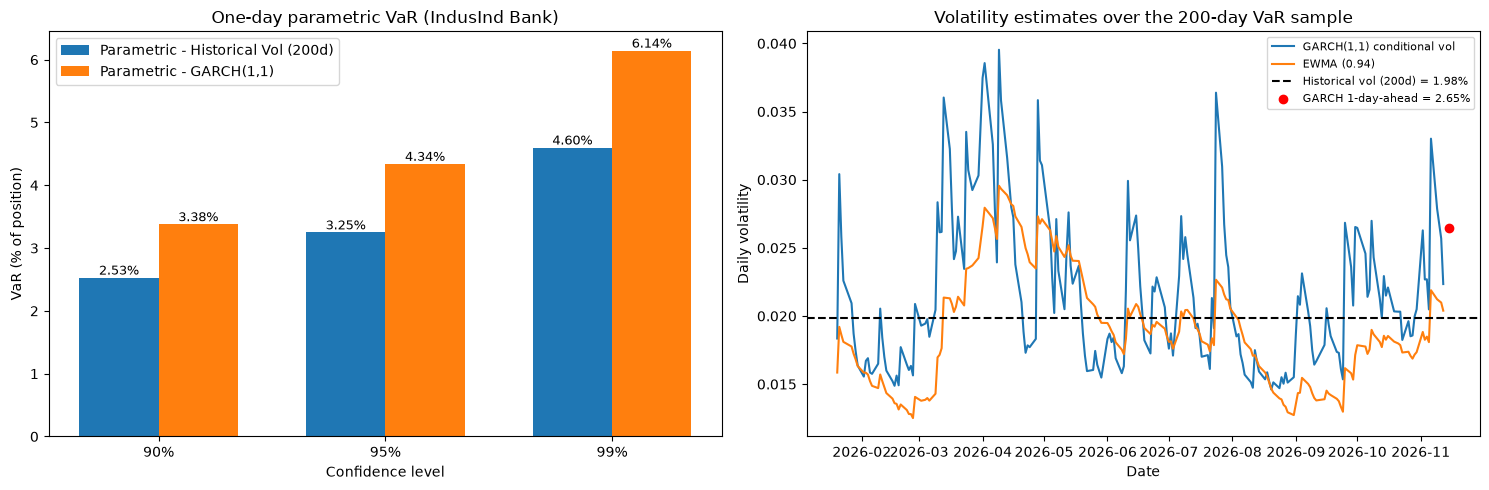

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: VaR by confidence level and volatility measure
x = np.arange(len(conf_levels)); width = 0.35
for i, (name, row) in enumerate(var_table.iterrows()):
    vals = [row[f"{int(c*100)}% VaR"] * 100 for c in conf_levels]
    bars = axes[0].bar(x + (i - 0.5) * width, vals, width, label=name)
    for b, v in zip(bars, vals):
        axes[0].text(b.get_x() + b.get_width()/2, v, f"{v:.2f}%", ha="center", va="bottom", fontsize=9)
axes[0].set_xticks(x); axes[0].set_xticklabels([f"{int(c*100)}%" for c in conf_levels])
axes[0].set_title("One-day parametric VaR (IndusInd Bank)")
axes[0].set_xlabel("Confidence level"); axes[0].set_ylabel("VaR (% of position)")
axes[0].legend()

# Right: volatility estimates over the VaR sample, with the inputs used
idx = var_returns.index
axes[1].plot(garch_vol.loc[idx], label="GARCH(1,1) conditional vol")
axes[1].plot(ewma_vol.loc[idx],  label="EWMA (0.94)")
axes[1].axhline(sigma_hist, color="black", linestyle="--", label=f"Historical vol ({HV_WINDOW}d) = {sigma_hist*100:.2f}%")
axes[1].scatter([idx[-1] + pd.Timedelta(days=3)], [sigma_garch], color="red", zorder=5, label=f"GARCH 1-day-ahead = {sigma_garch*100:.2f}%")
axes[1].set_title("Volatility estimates over the 200-day VaR sample")
axes[1].set_xlabel("Date"); axes[1].set_ylabel("Daily volatility")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig("task4_parametric_var.png", dpi=150)
plt.show()

var_table.to_csv("task4_parametric_var_table.csv")

## 7. Auto-generated observations (numbers update when you re-run)

In [10]:
r95 = var_table["95% VaR"]
hv_name, g_name = list(vol_inputs.keys())
ratio = sigma_garch / sigma_hist

print(f"- Historical vol ({HV_WINDOW}d) = {sigma_hist*100:.3f}% vs GARCH one-day-ahead = {sigma_garch*100:.3f}%  -> GARCH/Historical = {ratio:.2f}x.")
if ratio > 1.05:
    print("  GARCH is higher: recent volatility is above the 200-day average, so the conditional model is flagging a more turbulent present than the equal-weighted window.")
elif ratio < 0.95:
    print("  GARCH is lower: recent volatility has calmed relative to the 200-day average, which the equal-weighted window is slow to reflect.")
else:
    print("  The two are close: recent volatility is near its 200-day average.")
print(f"- 95% VaR: Historical = {r95[hv_name]*100:.3f}%, GARCH = {r95[g_name]*100:.3f}% (difference {abs(r95[g_name]-r95[hv_name])*100:.3f} pp).")
print(f"- Going from 90% to 99% scales VaR by roughly {z_vals[0.99]/z_vals[0.90]:.2f}x (ratio of z-values) when the mean is small.")
print(f"- Mean effect: mu_d = {mu_d*100:.4f}% per day shifts every VaR by {-mu_d*100:+.4f} pp (small next to z*sigma).")
print(f"- GARCH persistence alpha+beta = {alpha+beta:.3f}; EWMA 1-day-ahead vol = {sigma_ewma*100:.3f}%.")
print(f"- Excess kurtosis of the 200 returns = {kurtosis(var_returns):.2f} (0 for a normal): values well above 0 mean fat tails, so the normal 99% VaR is the most likely to understate risk.")

- Historical vol (200d) = 1.982% vs GARCH one-day-ahead = 2.645%  -> GARCH/Historical = 1.33x.
  GARCH is higher: recent volatility is above the 200-day average, so the conditional model is flagging a more turbulent present than the equal-weighted window.
- 95% VaR: Historical = 3.249%, GARCH = 4.341% (difference 1.091 pp).
- Going from 90% to 99% scales VaR by roughly 1.82x (ratio of z-values) when the mean is small.
- Mean effect: mu_d = 0.0106% per day shifts every VaR by -0.0106 pp (small next to z*sigma).
- GARCH persistence alpha+beta = 0.929; EWMA 1-day-ahead vol = 2.153%.
- Excess kurtosis of the 200 returns = 0.99 (0 for a normal): values well above 0 mean fat tails, so the normal 99% VaR is the most likely to understate risk.
